## 使用Unet在Mnist上进行简单的条件去噪(Conditional Denoising)

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [2]:
from torchvision import datasets, transforms
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))]) # [-1. 1]
train_data = datasets.MNIST(root="~/.cache/", transform=transform, train=True, download=True)

image, label = train_data[0]
channel, size, _ = image.shape
print(image.shape)

torch.Size([1, 28, 28])


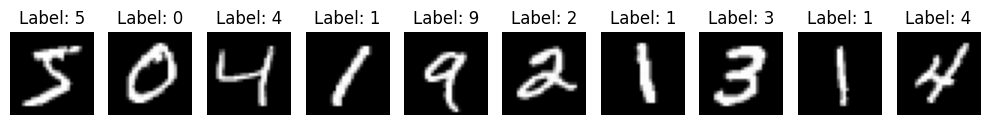

In [3]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

### Train

In [4]:
from torch.utils.data import DataLoader

from ddpm import DDPM, cosine_schedule
from model import ConditionalUnet

batch_size = 256
num_steps = 200
num_epoch = 25
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')

ddpm = DDPM(cosine_schedule(num_steps, device=device))
model = ConditionalUnet(
    in_size=28, 
    in_ch=1, 
    chs=[128, 256],
    n_steps=num_steps,
    n_class=10,
    p_uncond=0.2
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_dataloader = DataLoader(train_data, batch_size=batch_size, shuffle=True)

model.train()
for epoch in range(num_epoch):
    for imgs, labels in train_dataloader:
        imgs, labels = imgs.to(device), labels.to(device)

        t = torch.randint(0, num_steps, size=(imgs.size(0),), device=device)
        x_t, noise = ddpm.forward_step(imgs, t)
        loss = F.mse_loss(model(x_t, labels, t), noise)
        
        optimizer.zero_grad()
        loss.backward()
        # torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)  # 梯度裁剪
        optimizer.step()

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch + 1}/{num_epoch}, Loss: {loss.item():.4f}')
        

Epoch 1/25, Loss: 0.1237
Epoch 5/25, Loss: 0.0594
Epoch 10/25, Loss: 0.0474
Epoch 15/25, Loss: 0.0371
Epoch 20/25, Loss: 0.0425
Epoch 25/25, Loss: 0.0398


## 无标签随机生成

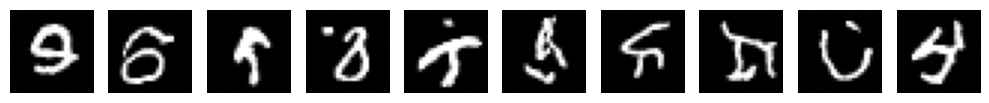

In [5]:
n_sample = 10
model.eval()
with torch.inference_mode():
    x_t = torch.randn(n_sample, 1, 28, 28, device=device)  # 使用初始数据
    label = torch.tensor([10]*n_sample, device=device) # random
    for i in reversed(range(num_steps)):
        t = torch.tensor([i] * x_t.size(0), device=device)
        eps = model(x_t, label, t)
        x_t = ddpm.reverse_step(x_t, eps, t)

x = x_t.clamp(-1.0, 1.0).cpu()
# print(x_t)
fig, axes = plt.subplots(1, n_sample, figsize=(n_sample, 2))
for i in range(n_sample):
    image = x[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

## 条件生成

The conditioning roughly follows the method described in [Classifier-Free Diffusion Guidance](https://arxiv.org/abs/2207.12598) (also used in [ImageGen](https://arxiv.org/abs/2205.11487)). The model infuses timestep embeddings $t_e$ and context embeddings $c_e$ with the U-Net activations at a certain layer $a_L$, via,

$$a_{L+1} = c_e  a_L + t_e.$$

(Though in our experimentation, we found variants of this also work, e.g. concatenating embeddings together.)

At training time, $c_e$ is randomly set to zero with probability $0.1$, so the model learns to do unconditional generation (say $\psi(z_t)$ for noise $z_t$ at timestep $t$) and also conditional generation (say $\psi(z_t, c)$ for context $c$). This is important as at generation time, we choose a weight, $w \geq 0$, to guide the model to generate examples with the following equation,

$$\hat{\epsilon}_{t} = (1+w)\psi(z_t, c) - w \psi(z_t).$$


Increasing $w$ produces images that are more typical but less diverse.

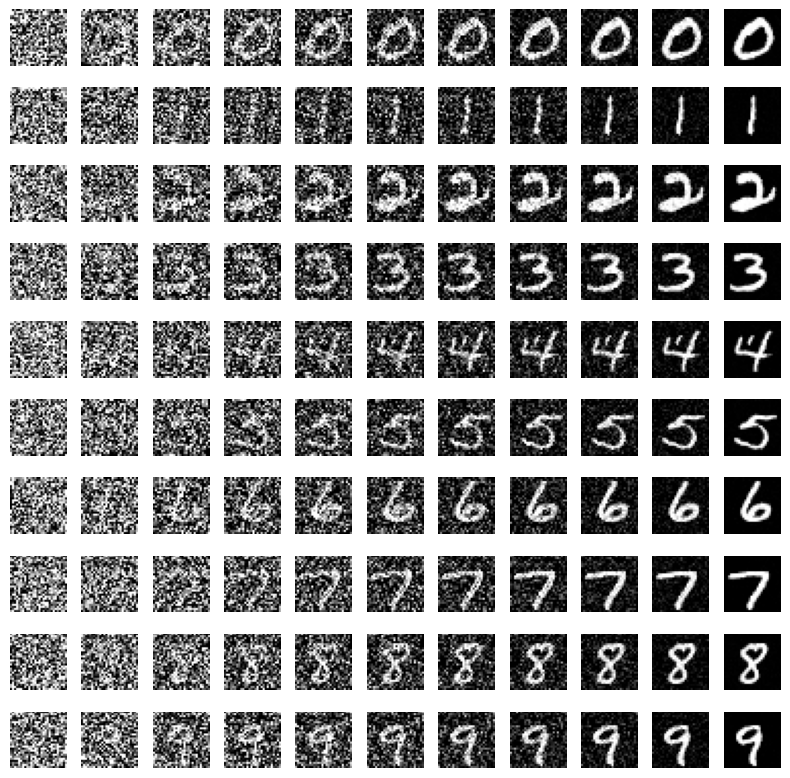

In [6]:
model.eval()
w = 2
with torch.inference_mode():
    x_t = torch.randn(10, 1, 28, 28, device=device)  # 使用初始数据
    label = torch.tensor(list(range(10)), device=device) # horse
    null = torch.tensor([10], device=device)
    x_seq = [x_t.squeeze(0).clamp(-1.0, 1.0).cpu()]
    for i in reversed(range(num_steps)):
        t = torch.tensor([i] * x_t.size(0), device=device)
        eps = (1 + w) * model(x_t, label, t) - w * model(x_t, null, t)
        x_t = ddpm.reverse_step(x_t, eps, t)
        x_seq.append(x_t.squeeze(0).clamp(-1.0, 1.0).cpu())

# plot picture
plt.rc('text',color='blue')
stride = num_steps // 10
x_seq = x_seq[::stride]
fig, axes = plt.subplots(10, 11, figsize=(8, 8))  # 10行11列的子图
for i in range(10):
    for step in range(n_sample + 1):
        image = x_seq[step][i]
        ax = axes[i, step]  # 获取当前子图
        ax.imshow(image[0], cmap='gray')  # 显示灰度图
        ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()